[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L5/BA_L5_svb/BA_L5_svb.ipynb)

# BA_L5_svb: The SVB Weekend Hour by Hour

*Quantlet of Lecture 5, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Hourly deviations from the 1 USD peg of USDC, DAI and USDT, and of USDC priced in USDT, from 8 to 17 March 2023, around the failure of Silicon Valley Bank (SVB) and the backstop of 12 March. Data: EODHD hourly aggregated prices.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

On Friday 10 March 2023 Silicon Valley Bank (SVB) failed; that evening Circle disclosed that 3.3 bn USD of its reserves were at SVB; on Sunday 12 March the Federal Reserve (Fed), the Federal Deposit Insurance Corporation (FDIC) and the Treasury announced a backstop for all SVB deposits.

The chart shows, hour by hour, the deviation $d_t = 10^4\,(P_t - 1)$ in basis points (bp) of USDC, DAI and USDT against the US dollar, and of USDC priced in USDT,

$$ d_t^{\,\mathrm{USDC/USDT}} = 10^4\left(\frac{P_t^{\mathrm{USDC}}}{P_t^{\mathrm{USDT}}} - 1\right). $$

All times are Coordinated Universal Time (UTC).

**Data:** EOD Historical Data (EODHD) hourly closing prices, 8 to 17 March 2023.

In [5]:
H = pd.concat({s: hourly(f'{s}-USD.CC') for s in ['USDC', 'USDT', 'DAI']}, axis=1)
z = H.loc['2023-03-08':'2023-03-17']

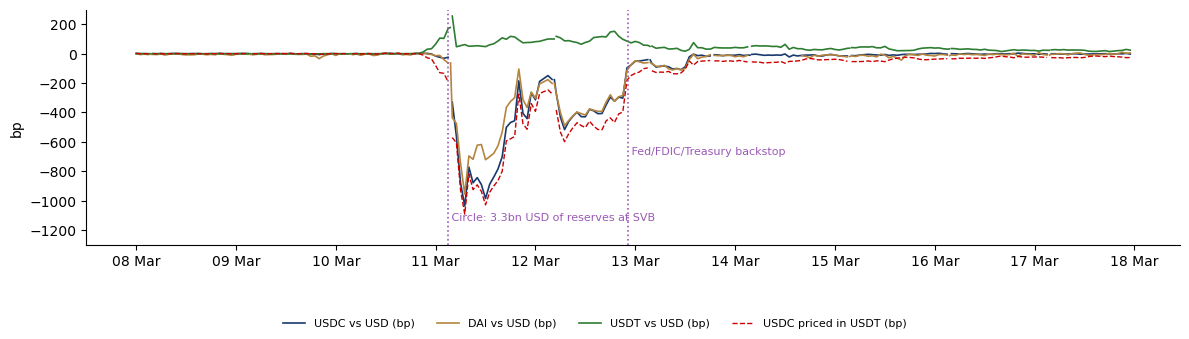

In [6]:
fig, ax = plt.subplots(figsize=(12, 3.4))
for s in ['USDC', 'DAI', 'USDT']:
    ax.plot(z.index, 1e4 * (z[s] - 1), color=COL[s], lw=1.2, label=f'{s} vs USD (bp)')
ax.plot(z.index, 1e4 * (z['USDC'] / z['USDT'] - 1), color=RED, ls='--', lw=1, label='USDC priced in USDT (bp)')
for t_, lab, yy in [('2023-03-11 03:00', 'Circle: 3.3bn USD of reserves at SVB', -1150), ('2023-03-12 22:15', 'Fed/FDIC/Treasury backstop', -700)]:
    ax.axvline(pd.Timestamp(t_), color=ETH, ls=':', lw=1.2)
    ax.text(pd.Timestamp(t_), yy, ' ' + lab, fontsize=8, color=ETH, va='bottom')
ax.set_ylabel('bp'); ax.set_ylim(-1300, 300)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
save(fig, 'ba_l5_svb', 0.15, ncol=4)

## Key numbers

In [7]:
zz = 1e4 * (z - 1)
print(pd.DataFrame({'lowest hourly deviation (bp)': zz.min().round(1), 'hour of the minimum (UTC)': zz.idxmin(),
                    'highest hourly deviation (bp)': zz.max().round(1)}).to_string())
back = zz['USDC'].loc[zz['USDC'].idxmin():]
print('\nUSDC first hour back above -100 bp:', back[back > -100].index[0], 'UTC')
print('USDC first hour back above -15 bp: ', back[back > -15].index[0], 'UTC')
usd = zz['USDC'].loc['2023-03-10':'2023-03-14']
first15 = usd[usd <= -15].index[0]
print(f'USDC: first hour at or below -15 bp {first15} UTC; {(back[back > -15].index[0] - first15) / pd.Timedelta(hours=1):.0f} hours '
      f'until back above -15 bp; {int((usd <= -100).sum())} hours at or below -100 bp')
s_svb = 3.3 / 40
print(f'\nredemption value of USDC with zero recovery on the SVB deposit (3.3 of about 40 bn USD of reserves): '
      f'{1 - s_svb:.4f} USD, a deviation of {-1e4 * s_svb:.0f} bp')

      lowest hourly deviation (bp) hour of the minimum (UTC)  highest hourly deviation (bp)
USDC                       -1036.0       2023-03-11 07:00:00                            3.6
USDT                          -1.8       2023-03-09 19:00:00                          255.9
DAI                         -955.4       2023-03-11 07:00:00                            9.4

USDC first hour back above -100 bp: 2023-03-12 22:00:00 UTC
USDC first hour back above -15 bp:  2023-03-13 14:00:00 UTC
USDC: first hour at or below -15 bp 2023-03-11 00:00:00 UTC; 62 hours until back above -15 bp; 45 hours at or below -100 bp

redemption value of USDC with zero recovery on the SVB deposit (3.3 of about 40 bn USD of reserves): 0.9175 USD, a deviation of -825 bp


**How to read it:** USDC and DAI reached their lowest hourly close at the same hour on Saturday 11 March, while USDT rose slightly above 1 (a flight to the other dollar).
DAI followed USDC because a large part of its collateral was USDC. USDC was back above $-100$ bp just before the backstop and above $-15$ bp only on Monday 13 March.
The market went below the redemption value under zero recovery: a peg can fail with reserves that cover more than 90% of the tokens.